# Own-data truss modelling and latent design

This notebook inspects the executed reference experiment. It replays saved own-trained weights, without repeating training or FE. Run from the repository root. The full generation/FE/training/search commands are in README.md.

The input has 378 upper-triangular adjacency entries and 27 natural offsets. The VAE mean has 48 components; the decoder returns 378 connection probabilities and 27 offsets. A new 48–128–128–9 head predicts nine FE stiffness components. The VAE class is adapted from the authors' public code; no author checkpoint is loaded.


In [1]:
from pathlib import Path
import csv,json,html
import numpy as np
from IPython.display import display,HTML,Image
ROOT=Path.cwd()
DATA=ROOT/'datasets/own_10000'
FIT=ROOT/'results/own_10000'
SEARCH=ROOT/'results/own_10000_search'
def table(path):
    with path.open() as f: rows=list(csv.DictReader(f))
    header=''.join('<th>'+html.escape(k)+'</th>' for k in rows[0])
    body=''.join('<tr>'+''.join('<td>'+html.escape(v)+'</td>' for v in row.values())+'</tr>' for row in rows)
    display(HTML('<table><tr>'+header+'</tr>'+body+'</table>'))
with np.load(DATA/'structures.npz') as source: data={k:source[k].copy() for k in source.files}
with np.load(DATA/'labels.npz') as source: labels={k:source[k].copy() for k in source.files}
with np.load(DATA/'splits.npz') as source: split=source['subset'].copy()
print('Adjacency:',data['adjacency'].shape,'offsets:',data['offsets'].shape,'FE stiffness:',labels['stiffness'].shape)
print('Split counts:',{s:int((split==s).sum()) for s in ['train','validation','test']})
print('Actual final topologies:',json.loads((DATA/'summary.json').read_text())['unique_topologies'])


Adjacency: (10000, 27, 27) offsets: (10000, 27) FE stiffness: (10000, 9)
Split counts: {'train': 8000, 'validation': 1000, 'test': 1000}
Actual final topologies: 499


## 1. Scratch training and independent sample test

The single 200-epoch fit uses training-only label normalization; validation selects the checkpoint. The 1,000 test examples do not choose epochs or settings. The loss is adjacency BCE + 10 offset MSE + 0.1 normalized property MSE + annealed KL. Thirty mean-decoding epochs precede native sampled reconstruction.

The native upstream sampler is retained: `exp(logvar)` scales one shared Gaussian scalar per example, while the KL code uses the source `logvar` expression. It is not the textbook independent-noise parameterization. Sampling variation is not calibrated property uncertainty.

All test topologies occur in training, but complete geometry inputs are distinct. Full connection recovery does not imply exact positions or stiffness.


Reconstruction FE subset:


subset,mode,n,exact_topologies,exact_fraction,mean_wrong_edges,matrix_accuracy,offset_RMSE,C_RMSE,C_normalized_MSE,valid_predicted_C
train,mean,8000,8000,1.0,0.0,1.0,0.012519567273557186,0.0015966693474735894,0.12324423406729385,7609
validation,mean,1000,1000,1.0,0.0,1.0,0.01668079011142254,0.001825213104524226,0.16760877552640496,943
test,mean,1000,1000,1.0,0.0,1.0,0.017004908993840218,0.0018196900839773905,0.16916154402124453,944
train,native_sample,8000,7997,0.999625,0.000625,0.9999982853223593,0.01277668122202158,0.0015966693474735894,0.12324423406729385,7609
validation,native_sample,1000,999,0.999,0.008,0.9999780521262003,0.016964931041002274,0.001825213104524226,0.16760877552640496,943
test,native_sample,1000,998,0.998,0.005,0.9999862825788751,0.01722857728600502,0.0018196900839773905,0.16916154402124453,944


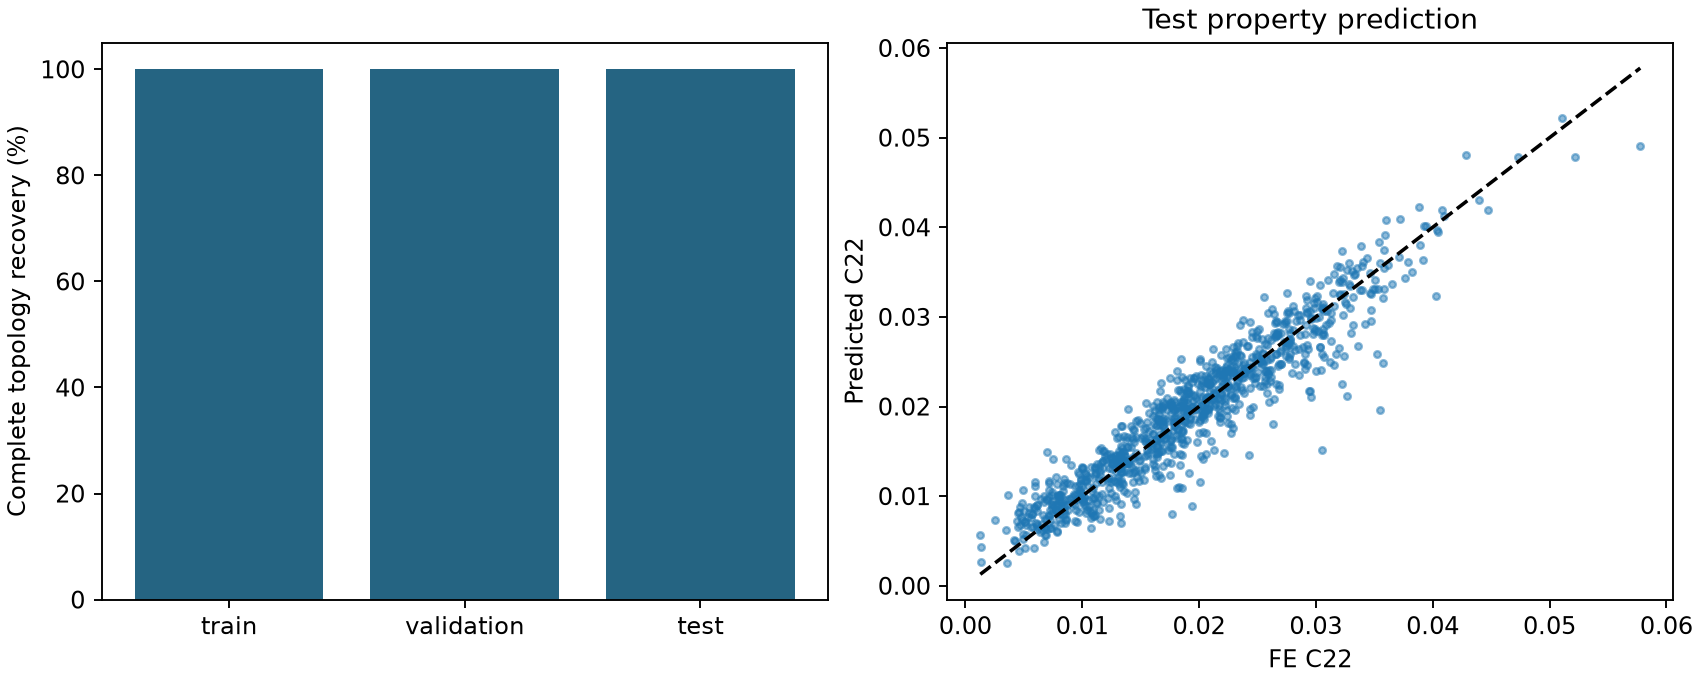

sample_id,status,reason,original_E22,reconstructed_E22,E22_change_percent,exact_topology
357,passed,,0.007203884344520168,0.007154553453521381,-0.6847818293517216,True
942,passed,,0.03219809124937897,0.03226037313604693,0.19343347462923433,True
1365,passed,,0.02793602799516356,0.02794264808784553,0.02369732978186878,True
1439,passed,,0.00856300038472382,0.008472592005711986,-1.0558025802862359,True
2313,passed,,0.007167438294750182,0.007233284007008321,0.9186784671221915,True
3590,passed,,0.01446773438740801,0.014539836877518333,0.4983675272133725,True
4148,passed,,0.0233856830379901,0.02334870475841407,-0.1581235814919757,True
4343,passed,,0.01671664803802045,0.01695109054949212,1.4024492885084117,True
4712,passed,,0.008817158245686215,0.008869355780047895,0.5919995185208027,True
7935,passed,,0.029736784855403417,0.02967016883484519,-0.22401890749841336,True


In [2]:
table(FIT/'metrics.csv')
display(Image(filename=str(FIT/'training_results.png')))
print('Reconstruction FE subset:')
table(FIT/'reconstruction_FE.csv')


## 2. Replay a preselected test reconstruction

Use the first of the twelve FE-check IDs fixed before training, not an example selected because it looked good. Decode the encoder mean and draw the original/reconstructed octant. This replays the own-trained checkpoint; it performs no new FE solve.


Selected epoch: 160 wrong undirected pairs: 0


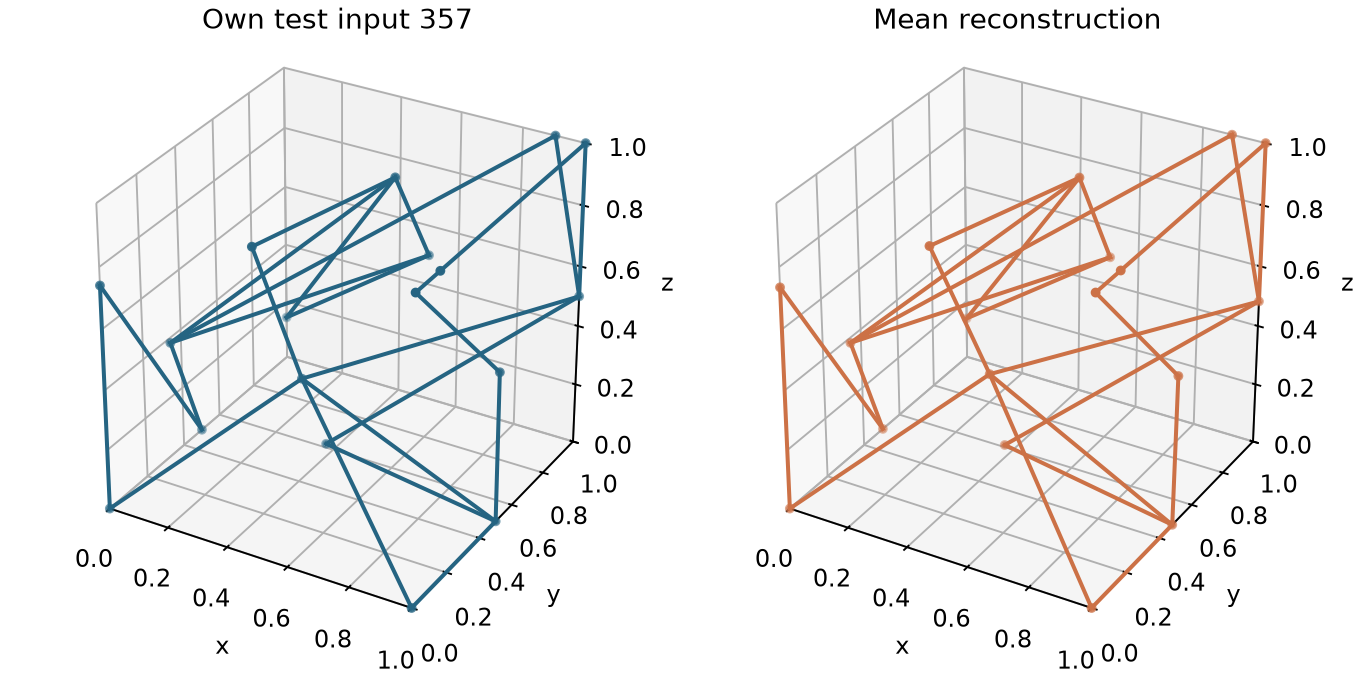

In [3]:
import torch
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from models import UPPER,EDGES,hard_geometry
from train import load_checkpoint
torch.set_num_threads(2)
vae,head,checkpoint=load_checkpoint(FIT)
i=json.loads((FIT/'fixed_FE_ids.json').read_text())[0]
with torch.no_grad():
    _,mu,_=vae.encoder(torch.tensor(data['adjacency'][i][UPPER][None],dtype=torch.float32),
                       torch.tensor(data['offsets'][i:i+1],dtype=torch.float32))
    probability,offsets=vae.decoder(mu)
recovered,points=hard_geometry(probability.numpy()[0],offsets.numpy()[0])
def draw(ax,a,p,title,color):
    for u,v in zip(*np.nonzero(np.triu(a,1))): ax.plot(*p[[u,v]].T,color=color,lw=1.7)
    active=a.sum(0)>0;ax.scatter(*p[active].T,s=10,color=color)
    ax.set(xlim=(0,1),ylim=(0,1),zlim=(0,1),box_aspect=(1,1,1),title=title,xlabel='x',ylabel='y',zlabel='z')
fig=plt.figure(figsize=(8,4),layout='constrained')
draw(fig.add_subplot(121,projection='3d'),data['adjacency'][i],data['positions'][i],f'Own test input {i}','#256482')
draw(fig.add_subplot(122,projection='3d'),recovered,points,'Mean reconstruction','#cc7146')
fig.savefig(FIT/'reconstruction_example.png',dpi=170);plt.close(fig)
print('Selected epoch:',checkpoint['epoch'],'wrong undirected pairs:',np.count_nonzero(recovered[EDGES]!=data['adjacency'][i][EDGES]))
display(Image(filename=str(FIT/'reconstruction_example.png')))


## 3. Freeze the own model and search for higher stiffness

Eight different training-source topologies initialize fixed local searches. Only the latent input changes. Actual FE checks are separate from surrogate predictions. Compare each endpoint against both its original source and its decoded starting geometry. All outcomes, including a disconnected candidate and two degraded endpoints, remain in the table.


Largest relative source improvement: 13.297788168486392 %
Highest absolute endpoint and budget: {'status': 'complete', 'starts': 8, 'valid_optimised_endpoints': 7, 'improved_vs_original': 5, 'new_FE_attempts': 32, 'earlier_reconstruction_FE_attempts': 12, 'post_training_FE_cap': 64, 'best_endpoint': {'source_id': 9221, 'original_FE_E22': 0.051064030774977745, 'decoded_start_FE_E22': 0.050897379715514966, 'endpoint_FE_E22': 0.05398881328947843, 'random_FE_E22': 0.0514527253997114, 'selected_step': 400, 'valid_surrogate_evaluations': 401, 'stop_reason': 'budget_completed', 'endpoint_status': 'passed', 'gain_vs_original_percent': 5.727676546705118, 'gain_vs_decoded_start_percent': 6.073856043754455}, 'own_model_sha256': 'b3a831c479f0df9f02988cacfb3facc76f8dcd474a5b645284f5c37f8198615f', 'weights_unchanged': True, 'stress_constraint_used': False, 'scope': 'Own-trained frozen model; training-source starts; bounded local search, not a global optimum or speed benchmark.', 'new_FE_solver_calls

source_id,original_FE_E22,decoded_start_FE_E22,endpoint_FE_E22,random_FE_E22,selected_step,valid_surrogate_evaluations,stop_reason,endpoint_status,gain_vs_original_percent,gain_vs_decoded_start_percent
5466,0.058252333840683235,0.05833460652592833,0.05153138096471951,0.04654275313098042,259,260,non_positive_surrogate_C,passed,-11.537654258360098,-11.662417844860162
7465,0.053370895324531514,0.052986582465382744,0.049275682109999185,0.049255726608582295,400,401,budget_completed,passed,-7.673120695522595,-7.003471789878068
4782,0.051274659283346534,0.05135073020210644,,0.03874148843141444,400,401,budget_completed,failed,,
9221,0.051064030774977745,0.050897379715514966,0.05398881328947843,0.0514527253997114,400,401,budget_completed,passed,5.727676546705118,6.073856043754455
6750,0.048450844052712584,0.04872777935533999,0.051740910889763576,0.0359483634157301,400,401,budget_completed,passed,6.790525328044916,6.183601170188324
8044,0.048263967525360676,0.047451511589673964,0.053717386251906016,0.04244332536333024,400,401,budget_completed,passed,11.299151325841162,13.204794646827622
3765,0.04762290152675598,0.046837834146340775,0.05291356537372639,0.04780412120357582,400,401,budget_completed,passed,11.109494964304002,12.971844958506228
8222,0.04755560295132046,0.047108536967189404,0.05387944629403352,0.04881866554878057,400,401,budget_completed,passed,13.297788168486392,14.372998532219295


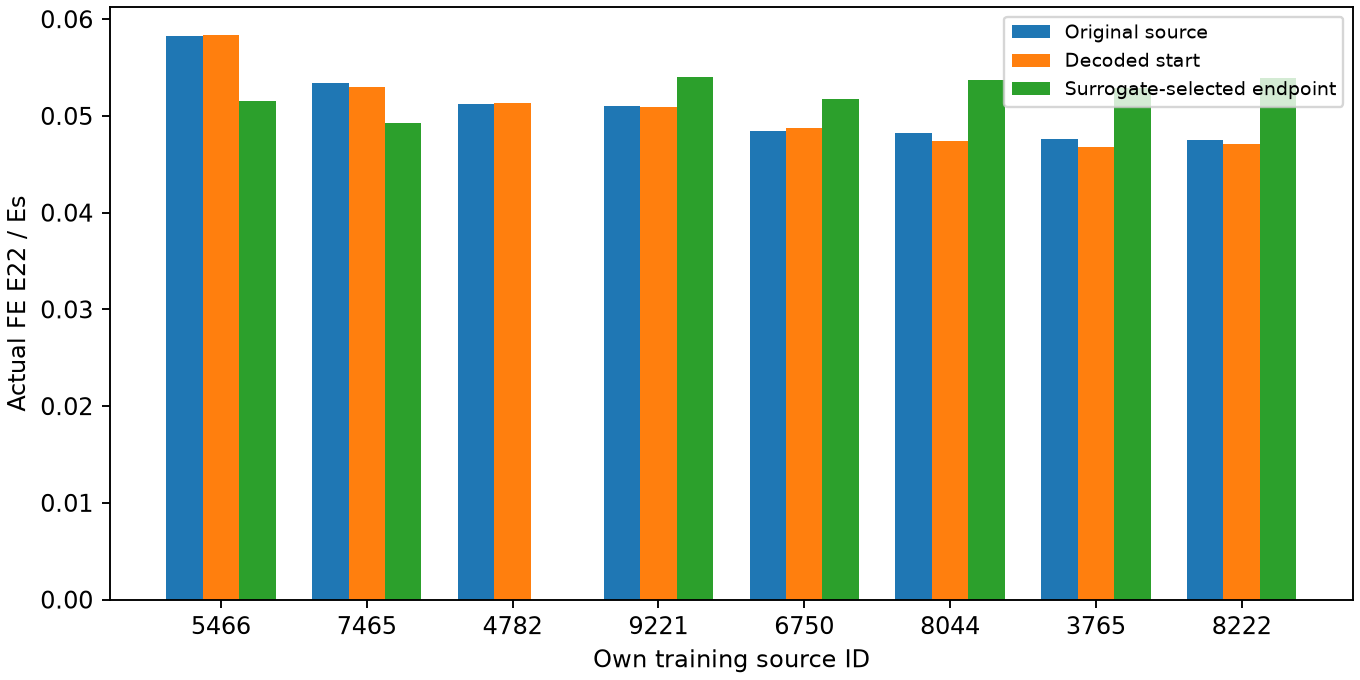

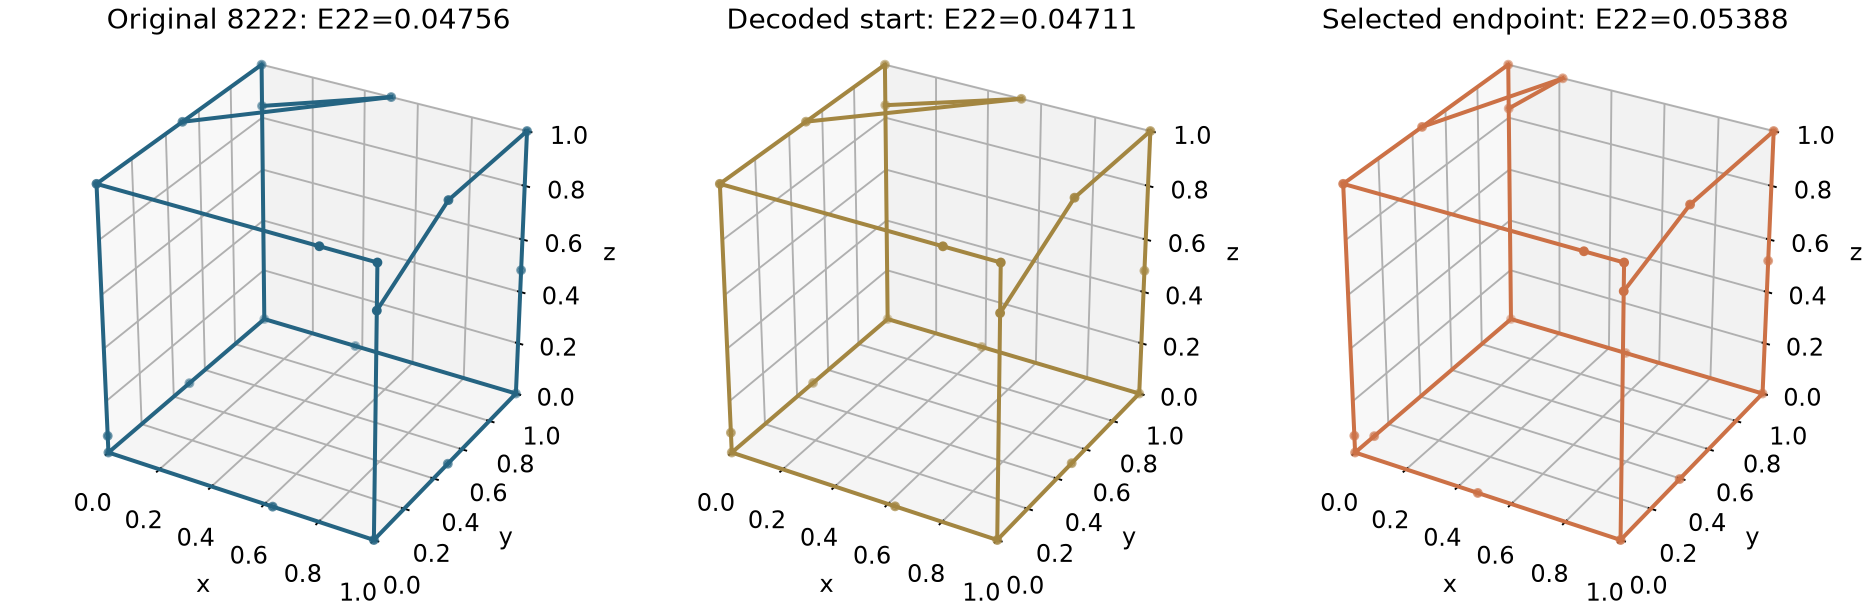

In [4]:
table(SEARCH/'comparison.csv')
display(Image(filename=str(SEARCH/'search_results.png')))
with (SEARCH/'comparison.csv').open() as f: rows=list(csv.DictReader(f))
valid=[r for r in rows if r['endpoint_status']=='passed' and int(r['selected_step'])>0]
winner=max(valid,key=lambda r:float(r['gain_vs_original_percent']));i=int(winner['source_id'])
with np.load(SEARCH/'candidates.npz') as source: candidates={k:source[k].copy() for k in source.files}
fig=plt.figure(figsize=(11,3.6),layout='constrained')
draw(fig.add_subplot(131,projection='3d'),data['adjacency'][i],data['positions'][i],f'Original {i}: E22={float(winner["original_FE_E22"]):.5f}','#256482')
for column,kind,title in [(2,'decoded_start','Decoded start'),(3,'surrogate_selected','Selected endpoint')]:
    j=np.flatnonzero((candidates['source_id']==i)&(candidates['kind']==kind))[0]
    value=winner['decoded_start_FE_E22'] if column==2 else winner['endpoint_FE_E22']
    draw(fig.add_subplot(130+column,projection='3d'),candidates['adjacency'][j],candidates['positions'][j],title+f': E22={float(value):.5f}', '#a38641' if column==2 else '#cc7146')
fig.savefig(SEARCH/'largest_relative_gain.png',dpi=170);plt.close(fig)
display(Image(filename=str(SEARCH/'largest_relative_gain.png')))
print('Largest relative source improvement:',winner['gain_vs_original_percent'],'%')
print('Highest absolute endpoint and budget:',json.loads((SEARCH/'results.json').read_text()))


The largest relative source improvement is 13.30%, while the highest absolute endpoint is a different candidate. Neither exceeds the strongest original training structure. This is evidence of local improvements in five of eight searches, not a global optimum or faster convergence. The random displacement is a single diagnostic draw per source, not a tuned benchmark. No stress constraint is imposed. The independent beam FE model does not establish joint strength or manufacturability.

The full dataset's 10,000 FE labels are an upfront cost, separate from post-training reconstruction/search checks. The selected own-trained checkpoint is unchanged during optimisation. See the two REPORT.md files and EXPERIMENT.md for the full recipe and limits.
